### 치이카와 유튜브 EDA v2

제목 기준 9개 소비·콘텐츠 유형의 다중 라벨 분석으로 콘텐츠 생산, 유형별 반응, 연도별 변화와 동시 출현을 탐색한다. 키워드 언급량, 캐릭터·작품명, 전체 시계열과 채널 구조를 함께 살펴본다.

v1의 6종 분류를 9종 다중 라벨 분류로 개편했다. 과거 분류와 결과는 v1에서 확인할 수 있다. 원본 CSV와 v1은 변경하지 않으며 파생 열은 분석용 복사본에만 추가한다.

분석 대상은 제목에 한글이 있고 히라가나·가타카나가 없는 영상이다. 이는 제목 언어에 따른 국내 생산의 대리 지표이며 한국인 제작자나 한국 시청자를 보장하지 않는다.

입력은 현재 프로젝트의 `youtube_analysis_merged.csv`와 `youtube_relevance_audit_merged.csv`다.

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_rows", 200)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 160)
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

PROJECT = Path(r"C:/Users/jaena/OneDrive/Desktop/data.project/KDT_Integral_Data_Project/02_csv/01_youtube")
MERGED_DIR = PROJECT / "1. videos" / "02. 정제" / "01. 병합_1,2차_정규화"
ANALYSIS_CSV = MERGED_DIR / "youtube_analysis_merged.csv"
AUDIT_CSV = MERGED_DIR / "youtube_relevance_audit_merged.csv"
for path in (ANALYSIS_CSV, AUDIT_CSV):
    if not path.exists():
        raise FileNotFoundError(f"입력 파일이 없습니다. 대체 데이터는 만들지 않습니다: {path}")

df_merged = pd.read_csv(ANALYSIS_CSV, encoding="utf-8-sig")
df_relevance_audit = pd.read_csv(AUDIT_CSV, encoding="utf-8-sig")

original_analysis_shape = df_merged.shape
original_audit_shape = df_relevance_audit.shape
original_analysis_ids = df_merged["video_id"].tolist()
original_audit_ids = df_relevance_audit["video_id"].tolist()
like_na_loaded = int(df_merged["like_count"].isna().sum())
comment_na_loaded = int(df_merged["comment_count"].isna().sum())

print("원본 analysis", original_analysis_shape)
print("원본 relevance", original_audit_shape)
print("로드 직후 좋아요 결측", like_na_loaded, "/ 댓글 결측", comment_na_loaded)

원본 analysis (13383, 9)
원본 relevance (14667, 8)
로드 직후 좋아요 결측 743 / 댓글 결측 1265


## 데이터 품질 확인

1차 정제 노트북은 좋아요·댓글 결측을 0으로 채워 `youtube_analysis_video_table.csv`에 저장했다. 이 노트북이 읽는 `youtube_analysis_merged.csv`에는 그 대체가 들어 있지 않다. 그래서 분석용 비율은 결측을 0으로 바꾸지 않고 계산한다. 게시 시각의 한국 시간 변환과 길이의 초 변환은 새 열에만 둔다.

In [2]:
quality = pd.DataFrame({
    "항목": [
        "행 수", "video_id 중복", "video_id 결측",
        "view_count 결측", "view_count 0", "view_count 음수",
        "like_count 결측", "like_count 음수",
        "comment_count 결측", "comment_count 음수",
        "publish_at 결측", "title 결측",
    ],
    "df_merged": [
        len(df_merged),
        int(df_merged["video_id"].duplicated().sum()),
        int(df_merged["video_id"].isna().sum()),
        int(df_merged["view_count"].isna().sum()),
        int((df_merged["view_count"] == 0).sum()),
        int((df_merged["view_count"] < 0).sum()),
        int(df_merged["like_count"].isna().sum()),
        int((df_merged["like_count"].dropna() < 0).sum()),
        int(df_merged["comment_count"].isna().sum()),
        int((df_merged["comment_count"].dropna() < 0).sum()),
        int(df_merged["publish_at"].isna().sum()),
        int(df_merged["title"].isna().sum()),
    ],
})
audit_status = df_relevance_audit["relevance_status"].value_counts(dropna=False)
print(quality.to_string(index=False))
print("\nrelevance_status")
print(audit_status.to_string())
print("audit video_id 중복", int(df_relevance_audit["video_id"].duplicated().sum()))
print("duration 결측", int(df_relevance_audit["duration"].isna().sum()))
print("review_details_unavailable", int((df_relevance_audit["relevance_status"] == "review_details_unavailable").sum()))

              항목  df_merged
             행 수      13383
     video_id 중복          0
     video_id 결측          0
   view_count 결측          0
    view_count 0          0
   view_count 음수          0
   like_count 결측        743
   like_count 음수          0
comment_count 결측       1265
comment_count 음수          0
   publish_at 결측          0
        title 결측          0

relevance_status
relevance_status
relevant           13383
review_no_match     1284
audit video_id 중복 0
duration 결측 0
review_details_unavailable 0


## 분석용 복사본과 관련성 분리

분석에 쓰는 영상은 `relevance_status == "relevant"`인 행이다. 코드는 relevant가 아닌 모든 감사 행을 `df_excluded`에 둔다. `review_no_match`만 골라 빼는 조건은 아니다. 제외한 행은 감사 표 원본에 그대로 둔다.

관련 판정은 수집 노트북의 이름 확인이다. 상세 제목·설명·태그에서 공백을 지운 뒤 `먼작귀`, `치이카와`, `ちいかわ`, `chiikawa` 중 하나가 있으면 relevant다. 상세 조회는 됐는데 이 이름이 없으면 `review_no_match`다. 이름이 없다고 사람이 무관하다고 본 것은 아니다.

`video_id`는 중복을 검사만 하고, 임의로 지우지 않는다. 분석 표와 relevant 감사 행은 `validate="one_to_one"`으로 결합한다.

In [3]:
df_analysis = df_merged.copy()
df_audit_all = df_relevance_audit.copy()

df_excluded = df_audit_all.loc[df_audit_all["relevance_status"] != "relevant"].copy()
df_audit = df_audit_all.loc[df_audit_all["relevance_status"] == "relevant"].copy()

print("relevant가 아닌 감사 행", len(df_excluded))
print(df_excluded["relevance_status"].value_counts(dropna=False).to_string())
print("분석 relevance", len(df_audit))

key_check = df_analysis.merge(df_audit[["video_id"]], on="video_id", how="outer", indicator=True)
print(key_check["_merge"].value_counts().to_string())

df = df_analysis.merge(df_audit, on="video_id", how="inner", validate="one_to_one")
print("결합 후", df.shape)
assert len(df) == len(df_analysis) == len(df_audit)
assert df["video_id"].is_unique
assert df_merged["like_count"].isna().sum() == like_na_loaded
assert df_merged["comment_count"].isna().sum() == comment_na_loaded

relevant가 아닌 감사 행 1284
relevance_status
review_no_match    1284
분석 relevance 13383
_merge
both          13383
left_only         0
right_only        0
결합 후 (13383, 16)


## 파생변수

좋아요율은 좋아요/조회수×100, 댓글률은 댓글/조회수×100, 참여율은 (좋아요+댓글)/조회수×100이다. 조회수가 0이거나 필요한 분자가 비어 있으면 그 비율은 결측이다. 좋아요나 댓글이 비어 있으면 참여율도 비운다. 결측을 0으로 채우지 않는다.

60초 이하는 길이 지표다. 유튜브가 쇼츠로 분류했다는 뜻은 아니다.

In [4]:
def duration_to_seconds(value):
    if pd.isna(value):
        return pd.NA
    match = re.fullmatch(r"PT(?:(\d+)H)?(?:(\d+)M)?(?:(\d+)S)?", str(value))
    if not match:
        return pd.NA
    hours, minutes, seconds = (int(part) if part else 0 for part in match.groups())
    return hours * 3600 + minutes * 60 + seconds

df["publish_at_kst"] = pd.to_datetime(df["publish_at"], utc=True).dt.tz_convert("Asia/Seoul")
df["collected_at_kst"] = pd.to_datetime(df["collected_at"], utc=True).dt.tz_convert("Asia/Seoul")
df["year"] = df["publish_at_kst"].dt.year
df["year_month"] = df["publish_at_kst"].dt.strftime("%Y-%m")
df["duration_sec"] = df["duration"].map(duration_to_seconds).astype("Int64")
df["is_short_60"] = df["duration_sec"].le(60)

df["like_rate"] = (df["like_count"] / df["view_count"] * 100).where(df["view_count"].gt(0) & df["like_count"].notna())
df["comment_rate"] = (df["comment_count"] / df["view_count"] * 100).where(df["view_count"].gt(0) & df["comment_count"].notna())
df["engagement_rate"] = ((df["like_count"] + df["comment_count"]) / df["view_count"] * 100).where(
    df["view_count"].gt(0) & df["like_count"].notna() & df["comment_count"].notna()
)

print("duration_sec 변환 실패", int(df["duration_sec"].isna().sum()))
print("publish_at_kst", df["publish_at_kst"].min(), "~", df["publish_at_kst"].max())
print("collected_at_kst", df["collected_at_kst"].min(), "~", df["collected_at_kst"].max())
print(
    "like_rate 계산 가능", int(df["like_rate"].notna().sum()),
    "/ comment_rate", int(df["comment_rate"].notna().sum()),
    "/ engagement", int(df["engagement_rate"].notna().sum()),
)

duration_sec 변환 실패 0
publish_at_kst 2022-01-03 16:04:09+09:00 ~ 2026-10-26 19:00:08+09:00
collected_at_kst 2026-10-26 19:07:25.207058+09:00 ~ 2026-10-27 20:28:42.016265+09:00
like_rate 계산 가능 12640 / comment_rate 12118 / engagement 11470


## 채널 ID 기반 관련성 검토와 제외

채널명 검색 실패는 삭제·무관 판정의 근거가 아니다. 수집 시점의 채널 ID와 영상 ID로 직접 확인 링크를 생성한다. 아래 3개 채널은 사용자가 무관하다고 확인한 대상으로, 그 판단을 출처로 기록해 분석에서 제외한다. 코드가 영상 내용을 자동 검증한 것은 아니다.

원본 CSV는 보존한다. 제외 영상은 `channel_review_videos`, 제외 전 후보 집합은 `df_before_channel_review`에 남긴다. `APPLY_CHANNEL_EXCLUSIONS=False`로 바꾸면 비교용으로 제외 전 분석을 실행할 수 있다. 링크의 현재 접근 가능 여부와 실제 영상 내용은 별도 확인이 필요하다.

제목 본문·해시태그·설명·태그별 명칭 매칭을 구분한다. 본문 매칭 여부만으로 관련성을 자동 확정하지 않는다.

In [5]:
APPLY_CHANNEL_EXCLUSIONS = True
CHANNEL_REVIEW = {
    "UC_bq6EA8U2xCcBgMjshCh0Q": "Antistress Toys",
    "UCDtDKN4I6SS6rCiUi7lPyXg": "NekYos",
    "UCiHMmtaCy2vIcs17gFqC4fQ": "Favorite Toys",
}
df_before_channel_review = df.copy()
channel_review_videos = df.loc[df["channel_id"].isin(CHANNEL_REVIEW)].copy()
channel_review_videos["channel_url"] = "https://www.youtube.com/channel/" + channel_review_videos["channel_id"]
channel_review_videos["video_url"] = "https://www.youtube.com/watch?v=" + channel_review_videos["video_id"]
channel_review_videos["title_hashtags"] = channel_review_videos["title"].fillna("").str.findall(r"[#＃][^\s#＃]+").str.join(" ")
channel_review_videos["title_body"] = channel_review_videos["title"].fillna("").str.replace(r"[#＃][^\s#＃]+", " ", regex=True).str.strip()
name_pattern = r"치이카와|먼작귀|ちいかわ|chiikawa"
for field in ["title_body", "title_hashtags", "description", "tags"]:
    channel_review_videos[f"match_{field}"] = channel_review_videos[field].fillna("").str.replace(r"\s+", "", regex=True).str.contains(name_pattern, case=False, regex=True)
channel_review_videos["review_source"] = "사용자 확인: 치이카와 무관 채널"
channel_review_videos["availability_status"] = "미확인: 검색 실패로 삭제 여부를 판단하지 않음"
channel_review_summary = channel_review_videos.groupby(["channel_id", "channel"]).agg(
    영상수=("video_id", "size"), 누적조회수=("view_count", "sum"),
    제목본문매칭=("match_title_body", "sum"), 제목해시태그매칭=("match_title_hashtags", "sum"),
).reset_index()
channel_review_summary["채널직접링크"] = "https://www.youtube.com/channel/" + channel_review_summary["channel_id"]
print(channel_review_summary.to_string(index=False))
print("\n수집된 영상 직접 확인 목록")
print(channel_review_videos[["channel", "title", "title_body", "match_title_body", "match_title_hashtags", "match_description", "match_tags", "video_url"]].to_string(index=False))
missing_ids = set(CHANNEL_REVIEW) - set(channel_review_videos["channel_id"])
print("수집 데이터에 없는 대상 채널 ID:", sorted(missing_ids))
if APPLY_CHANNEL_EXCLUSIONS:
    df = df_before_channel_review.loc[~df_before_channel_review["channel_id"].isin(CHANNEL_REVIEW)].copy()
else:
    df = df_before_channel_review.copy()
print("\n제외 적용:", APPLY_CHANNEL_EXCLUSIONS, "/ 제외 전:", len(df_before_channel_review), "/ 제외 후:", len(df))
if APPLY_CHANNEL_EXCLUSIONS:
    assert len(df_before_channel_review) == len(df) + len(channel_review_videos)
    assert not df["channel_id"].isin(CHANNEL_REVIEW).any()
assert df["video_id"].is_unique


              channel_id         channel  영상수       누적조회수  제목본문매칭  제목해시태그매칭                                                   채널직접링크
UCDtDKN4I6SS6rCiUi7lPyXg          NekYos   18  46225606.0       0        18 https://www.youtube.com/channel/UCDtDKN4I6SS6rCiUi7lPyXg
UC_bq6EA8U2xCcBgMjshCh0Q Antistress Toys   98 335079386.0       0        98 https://www.youtube.com/channel/UC_bq6EA8U2xCcBgMjshCh0Q
UCiHMmtaCy2vIcs17gFqC4fQ   Favorite Toys   76  42312253.0       0        76 https://www.youtube.com/channel/UCiHMmtaCy2vIcs17gFqC4fQ

수집된 영상 직접 확인 목록
        channel                                                     title                 title_body  match_title_body  match_title_hashtags  match_description  match_tags                                   video_url
         NekYos                      Sick🤒 #컨셉 #치이카와 #쇼츠 #감기 #인형계 #추천 #조이                      Sick🤒             False                  True              False       False https://www.youtube.com/watch?v=7G00alTJpr4
         NekYos    

## 국내 제목 부분집합

수집은 한국 시간 연도와 `regionCode=KR`을 사용했지만 일본어 제목도 포함된다. 이하 분석은 제목에 한글이 있고 히라가나·가타카나가 없는 영상에 적용한다.

In [6]:
title = df["title"].fillna("")
df["has_hangul"] = title.str.contains(r"[가-힣]", regex=True)
df["has_kana"] = title.str.contains("[ぁ-んァ-ン]", regex=True)
df["is_korean_title"] = df["has_hangul"] & ~df["has_kana"]

scope_counts = pd.DataFrame({
    "구분": ["확정 제외 반영 전체", "한글만", "한글+가나", "한글 없음"],
    "영상 수": [
        len(df),
        int(df["is_korean_title"].sum()),
        int((df["has_hangul"] & df["has_kana"]).sum()),
        int((~df["has_hangul"]).sum()),
    ],
})
print(scope_counts.to_string(index=False))

df_kr = df.loc[df["is_korean_title"]].copy()
print("국내 분석 대상", len(df_kr))
print("국내 집합에서 제외", len(df) - len(df_kr), "건. 사유: 제목이 국내 생산 대리 지표(한글만, 가나 없음)에 해당하지 않음")
N_KR = len(df_kr)

         구분  영상 수
확정 제외 반영 전체 13191
        한글만  8749
      한글+가나   982
      한글 없음  3460
국내 분석 대상 8749
국내 집합에서 제외 4442 건. 사유: 제목이 국내 생산 대리 지표(한글만, 가나 없음)에 해당하지 않음


## 추가 관련성 검토 패턴 — 자동 제외하지 않음

이미 제외한 세 채널을 뺀 현재 분석 집합에서 검토 후보를 찾는다. 제목 본문과 해시태그를 분리하고, 명칭의 등장 위치·본문 언어·채널 내 반복 해시태그·앞서 발견한 묶음·다른 콘텐츠명 후보를 기록한다.

1순위는 제목 본문에 관련 명칭이 없으면서 알려진 태그 묶음, 다른 콘텐츠명 후보 또는 본문에 한글 없이 관련 해시태그만 있는 경우다. 2순위는 관련 명칭이 제목 해시태그/설명/태그에만 있는 경우, 3순위는 반복 해시태그 참고 대상이다. 동일 묶음 3편 기준은 검토 편의를 위한 기준이며 무관성을 입증하지 않는다.

관련 작품의 공식 영상, 캐릭터 이름만 쓴 제목, 콜라보도 검출될 수 있다. 후보 조회수는 오염된 조회수로 확정하지 않는다. 패턴 미검출도 관련성 확인을 뜻하지 않는다. 직접 링크로 내용을 확인하고 `review_decision`, `review_evidence`에 근거를 기록한 뒤 제외 여부를 결정한다. 이 코드는 현재 분석 표본 밖의 영상이나 온라인 접속 상태를 점검하지 않는다.

In [7]:
# 자동 판정은 관련성 확정이 아니라 검토 우선순위다. df_kr는 변경하지 않는다.
pattern_audit = df_kr.copy()
pt = pattern_audit["title"].fillna("")
pattern_audit["title_body"] = pt.str.replace(r"[#＃][^\s#＃]+", " ", regex=True).str.replace(r"\s+", " ", regex=True).str.strip()
tag_lists = pt.str.findall(r"[#＃]([^\s#＃]+)")
pattern_audit["title_hashtags"] = tag_lists.str.join(" ")
pattern_audit["hashtag_signature"] = tag_lists.map(lambda xs: "|".join(sorted(set(x.casefold() for x in xs))))
pattern_audit["hashtag_count"] = tag_lists.map(len)
for field in ["title_body", "title_hashtags", "description", "tags"]:
    pattern_audit[f"name_in_{field}"] = pattern_audit[field].fillna("").str.replace(r"\s+", "", regex=True).str.contains(r"치이카와|먼작귀|ちいかわ|chiikawa", case=False, regex=True)
no_body_name = ~pattern_audit["name_in_title_body"]
pattern_audit["flag_hashtag_only_title"] = no_body_name & pattern_audit["name_in_title_hashtags"]
pattern_audit["flag_no_hangul_body"] = ~pattern_audit["title_body"].str.contains(r"[가-힣]")
pattern_audit["same_signature_in_channel"] = pattern_audit.groupby(["channel_id", "hashtag_signature"])["video_id"].transform("size")
pattern_audit["flag_repeated_hashtags"] = pattern_audit["hashtag_count"].ge(3) & pattern_audit["same_signature_in_channel"].ge(3)
# 앞서 발견한 해시태그 묶음의 동시 등장. 단독 키워드는 무관 근거가 아니다.
pattern_audit["flag_known_tag_bundle"] = tag_lists.map(lambda xs: {"치이카와", "인형계", "감기", "조이"}.issubset(set(xs)))
# 예시 사전은 비포괄적이며, 콜라보/여러 IP 소개도 검출할 수 있다.
OTHER_TOPIC_PATTERN = r"rainbow\s*friends|레인보우\s*프렌즈|mcqueen|맥퀸|skibidi|스키비디|poppy\s*playtime|huggy\s*wuggy|허기워기|m\s*&\s*m"
pattern_audit["flag_other_topic_body"] = pattern_audit["title_body"].str.contains(OTHER_TOPIC_PATTERN, case=False, regex=True)
pattern_audit["flag_metadata_only"] = no_body_name & ~pattern_audit["name_in_title_hashtags"] & (pattern_audit["name_in_description"] | pattern_audit["name_in_tags"])
pattern_audit["is_doll_keyword"] = pt.str.contains("인형계", regex=False)
high = no_body_name & (pattern_audit["flag_known_tag_bundle"] | pattern_audit["flag_other_topic_body"] | (pattern_audit["name_in_title_hashtags"] & pattern_audit["flag_no_hangul_body"]))
medium = pattern_audit["flag_hashtag_only_title"] | pattern_audit["flag_metadata_only"]
low = pattern_audit["flag_repeated_hashtags"]
pattern_audit["review_priority"] = np.select([high, medium, low], ["1_우선 확인", "2_문맥 확인", "3_반복 패턴 참고"], default="패턴 미검출")
pattern_audit["review_status"] = "미검토"
pattern_audit["review_decision"] = ""
pattern_audit["review_evidence"] = ""
pattern_audit["video_url"] = "https://www.youtube.com/watch?v=" + pattern_audit["video_id"]
pattern_audit["channel_url"] = "https://www.youtube.com/channel/" + pattern_audit["channel_id"]
reason_columns = {
    "flag_hashtag_only_title": "제목 본문 명칭 없음·해시태그에 있음",
    "flag_no_hangul_body": "제목 본문 한글 없음",
    "flag_repeated_hashtags": "채널 내 동일 해시태그 묶음 3편 이상",
    "flag_known_tag_bundle": "치이카와·인형계·감기·조이 묶음",
    "flag_other_topic_body": "다른 콘텐츠명 후보",
    "flag_metadata_only": "설명·태그에만 관련 명칭",
}
pattern_audit["review_reasons"] = pattern_audit.apply(lambda row: " / ".join(label for col, label in reason_columns.items() if row[col]), axis=1)
review_candidates = pattern_audit.loc[pattern_audit["review_priority"] != "패턴 미검출"].sort_values(["review_priority", "view_count"], ascending=[True, False]).copy()
pattern_channel_summary = review_candidates.groupby(["channel_id", "channel"]).agg(
    검토후보수=("video_id", "size"), 후보누적조회수=("view_count", "sum"),
    우선확인수=("review_priority", lambda s: s.eq("1_우선 확인").sum()),
    인형계후보수=("is_doll_keyword", "sum"),
).reset_index()
channel_totals = pattern_audit.groupby("channel_id").size()
pattern_channel_summary["채널전체영상수"] = pattern_channel_summary["channel_id"].map(channel_totals)
pattern_channel_summary["후보비율"] = pattern_channel_summary["검토후보수"] / pattern_channel_summary["채널전체영상수"]
pattern_channel_summary["channel_url"] = "https://www.youtube.com/channel/" + pattern_channel_summary["channel_id"]
pattern_channel_summary = pattern_channel_summary.sort_values("후보누적조회수", ascending=False)
print("검토 우선순위별 영상 수")
print(pattern_audit["review_priority"].value_counts().to_string())
print("\n후보 조회수 영향 상위 20채널: 무관 판정 목록이 아님")
print(pattern_channel_summary.head(20).to_string(index=False))
print("\n우선 확인 영상 상위 30편")
print(review_candidates.loc[review_candidates["review_priority"].eq("1_우선 확인"), ["channel", "title", "view_count", "review_reasons", "video_url"]].head(30).to_string(index=False))
print("\n남은 인형계 영상의 검토 우선순위")
print(pattern_audit.loc[pattern_audit["is_doll_keyword"]].groupby("review_priority").agg(영상수=("video_id", "size"), 누적조회수=("view_count", "sum")).to_string())
assert pattern_audit["video_id"].is_unique
assert len(pattern_audit) == len(df_kr) == N_KR
assert not pattern_audit["channel_id"].isin(CHANNEL_REVIEW).any() if APPLY_CHANNEL_EXCLUSIONS else True


검토 우선순위별 영상 수
review_priority
패턴 미검출        5706
1_우선 확인       1738
2_문맥 확인       1263
3_반복 패턴 참고      42

후보 조회수 영향 상위 20채널: 무관 판정 목록이 아님
              channel_id            channel  검토후보수    후보누적조회수  우선확인수  인형계후보수  채널전체영상수     후보비율                                              channel_url
UCh2iSDuh2nSJ3i3bO3u-iuA             오늘은뭐볼까     16 17171646.0      0       0       18 0.888889 https://www.youtube.com/channel/UCh2iSDuh2nSJ3i3bO3u-iuA
UCW83PKdGW3A-xqt3JEQaMRA                 조이      5 14489374.0      1       5        6 0.833333 https://www.youtube.com/channel/UCW83PKdGW3A-xqt3JEQaMRA
UCfv_rbi5OclKy25qQXW8HLw              liaaa      1 13171481.0      1       1        1 1.000000 https://www.youtube.com/channel/UCfv_rbi5OclKy25qQXW8HLw
UCDHAKPpDjonLvFpFyISLQqw                마금이      4 10372208.0      0       0       12 0.333333 https://www.youtube.com/channel/UCDHAKPpDjonLvFpFyISLQqw
UCHZFS8JwwB05go1h0LKCekg          Ashar Alo     70  8075022.0     70      65       70 1.000000 https:

## 검토 목록 저장 및 확정 판정 적용

`3. code/relevance_review` 폴더에 영상별·채널별 후보 목록을 저장한다. 후보 목록은 재실행 시 갱신되지만, 수동 판정 파일 `review_decisions.csv`는 덮어쓰지 않는다.

수동 판정 파일에 영상 ID(`video_id`), 판정(`review_decision`: 관련/무관/보류), 확인 근거(`review_evidence`)를 입력하고 위에서부터 다시 실행한다. `무관`으로 명시하고 근거를 기록한 영상만 추가 제외한다. 빈 판정·보류·미검토는 유지하므로 최종 관련성 검증이 끝난 표본이라는 뜻은 아니다. 후보라는 이유로 채널 전체를 제외하지 않는다.

확정 제외분과 적용 전후 영상 수·조회수·인형계 키워드 영상 수를 별도로 보존한다. 이후 키워드·캐릭터·채널·9종·시계열 집계는 갱신된 분석 대상을 사용한다.

In [8]:
import os
REVIEW_DIR = Path(os.environ.get("YOUTUBE_REVIEW_DIR", str(PROJECT / "3. code" / "relevance_review")))
REVIEW_DIR.mkdir(parents=True, exist_ok=True)
DECISION_FILE = REVIEW_DIR / "review_decisions.csv"
decision_columns = ["video_id", "review_decision", "review_evidence"]
if not DECISION_FILE.exists():
    pd.DataFrame(columns=decision_columns).to_csv(DECISION_FILE, index=False, encoding="utf-8-sig")
decisions = pd.read_csv(DECISION_FILE, dtype=str, keep_default_na=False)

def validate_review_decisions(table, known_ids):
    if not set(decision_columns).issubset(table.columns):
        raise ValueError("검토 파일에 video_id, review_decision, review_evidence 열이 필요합니다.")
    table = table[decision_columns].copy()
    for col in decision_columns:
        table[col] = table[col].str.strip()
    table = table.loc[table.ne("").any(axis=1)]
    if table["video_id"].eq("").any() or table["video_id"].duplicated().any():
        raise ValueError("검토 파일의 영상 ID가 비어 있거나 중복됩니다.")
    if not table["review_decision"].isin(["", "관련", "무관", "보류"]).all():
        raise ValueError("판정은 빈값, 관련, 무관, 보류 중 하나여야 합니다.")
    if (table["review_decision"].ne("") & table["review_evidence"].eq("")).any():
        raise ValueError("판정한 영상에는 확인 근거를 기록하세요.")
    unknown = set(table["video_id"]) - set(known_ids)
    if unknown:
        raise ValueError(f"현재 분석 후보에 없는 영상 ID: {sorted(unknown)}")
    return table

decisions = validate_review_decisions(decisions, pattern_audit["video_id"])
review_export = review_candidates.drop(columns=["review_decision", "review_evidence", "review_status"]).merge(decisions, on="video_id", how="left", validate="one_to_one")
review_export[["review_decision", "review_evidence"]] = review_export[["review_decision", "review_evidence"]].fillna("")
review_export["review_status"] = np.where(review_export["review_decision"].eq(""), "미검토", "판정 기록 있음")
review_export.to_csv(REVIEW_DIR / "additional_review_videos.csv", index=False, encoding="utf-8-sig")
pattern_channel_summary.to_csv(REVIEW_DIR / "additional_review_channels.csv", index=False, encoding="utf-8-sig")
exclude_ids = set(decisions.loc[decisions["review_decision"].eq("무관"), "video_id"])
df_kr_before_manual_review = df_kr.copy()
manual_excluded = df_kr.loc[df_kr["video_id"].isin(exclude_ids)].merge(decisions, on="video_id", how="left", validate="one_to_one")
df_kr = df_kr.loc[~df_kr["video_id"].isin(exclude_ids)].copy()
df = df.loc[~df["video_id"].isin(exclude_ids)].copy()
N_KR = len(df_kr)
if N_KR == 0:
    raise ValueError("분석 대상이 0편입니다. 검토 판정을 확인하세요.")
review_impact = pd.DataFrame([
    {"구분": label, "영상수": len(frame), "누적조회수": frame["view_count"].sum(),
     "인형계키워드영상수": int(frame["title"].fillna("").str.contains("인형계", regex=False).sum())}
    for label, frame in [("수동 검토 적용 전", df_kr_before_manual_review), ("무관 확정 제외", manual_excluded), ("수동 검토 적용 후", df_kr)]
])
manual_excluded.to_csv(REVIEW_DIR / "confirmed_excluded_videos.csv", index=False, encoding="utf-8-sig")
review_impact.to_csv(REVIEW_DIR / "review_impact.csv", index=False, encoding="utf-8-sig")
assert len(df_kr_before_manual_review) == N_KR + len(manual_excluded)
assert not df_kr["video_id"].isin(exclude_ids).any()
print("검토 파일 폴더:", REVIEW_DIR)
print("수동 판정 입력 파일:", DECISION_FILE)
print(review_impact.to_string(index=False))
print("미검토·보류는 유지합니다. 추가 제외는 근거가 기록된 무관 판정만 적용합니다.")


검토 파일 폴더: C:\Users\jaena\OneDrive\문서\ChatGPT\data.project\youtube_v2_cleanup\relevance_review
수동 판정 입력 파일: C:\Users\jaena\OneDrive\문서\ChatGPT\data.project\youtube_v2_cleanup\relevance_review\review_decisions.csv
        구분  영상수       누적조회수  인형계키워드영상수
수동 검토 적용 전 8749 716567527.0       1670
  무관 확정 제외    0         0.0          0
수동 검토 적용 후 8749 716567527.0       1670
미검토·보류는 유지합니다. 추가 제외는 근거가 기록된 무관 판정만 적용합니다.


## 제목 단어 분포

콘텐츠 유형은 제목만 사용한다. 설명의 성우 크레딧 때문에 본편 영상을 더빙 창작으로 분류하지 않기 위한 기준이다. 캐릭터·작품명은 제목, 설명, 태그를 합친 `search_text`를 사용한다.

Kiwi 형태소 분석이 아니라 `[가-힣]{2,}`로 두 글자 이상 연속된 한글 문자열을 추출한다. 출현 횟수는 같은 제목 안의 반복도 센다. 언급 영상 수는 영상별 동일 단어를 한 번만 센다.

문자열 출현 횟수, 단어별 고유 영상 수, 사전 키워드 매칭, 유형별 OR 집계를 구분한다.

In [9]:
hangul_tokens = df_kr["title"].fillna("").str.findall(r"[가-힣]{2,}")
token_counts = (
    hangul_tokens.explode()
    .value_counts()
    .head(40)
    .rename_axis("제목 단어")
    .reset_index(name="제목 단어 출현 횟수")
)
token_video = (
    df_kr[["video_id"]].assign(제목_단어=hangul_tokens)
    .explode("제목_단어")
    .dropna(subset=["제목_단어"])
    .drop_duplicates(["video_id", "제목_단어"])
)
token_video_counts = (
    token_video.groupby("제목_단어").size()
    .sort_values(ascending=False)
    .head(40)
    .rename("언급 영상 수")
    .rename_axis("제목 단어")
    .reset_index()
)
token_video_counts["언급 영상 비율"] = (token_video_counts["언급 영상 수"] / N_KR).round(4)
print("출현 횟수 상위 40개. 같은 제목의 반복을 포함한다")
print(token_counts.to_string(index=False))
print("\n고유 영상 수 상위 40개. 한 제목에서 같은 단어는 한 번만 센다")
print(token_video_counts.to_string(index=False))

출현 횟수 상위 40개. 같은 제목의 반복을 포함한다
    제목 단어  제목 단어 출현 횟수
     치이카와         8536
      먼작귀         2194
      인형계         1669
       컨셉         1632
       쇼츠         1398
       추천         1337
       감기         1155
       조이          965
     브이로그          444
      우사기          434
      귀여운          410
       가챠          401
     하치와레          395
      산리오          354
       인형          338
      랜덤깡          323
      피규어          291
      언박싱          291
       일본          271
       작고          270
       먼가          262
     인형뽑기          262
       뽑기          257
       굿즈          248
       녀석          244
      오타쿠          243
      만들기          243
       포장          236
     전편공개          235
     알고리즘          184
     포카포장          178
      콜라보          168
       신상          166
       도쿄          160
먼가작고귀여운녀석          157
       리뷰          155
      아이브          150
       키링          149
       랜덤          145
      극장판          137

고유 영상 수 상위 40개. 한 제목에서 같은 

## 캐릭터·작품명 분류

11종 캐릭터와 2종 작품명을 제목·설명·태그에서 판별한다. 캐릭터는 복수 언급을 허용한다. `시사(?!리즈)`, `파자마\s*파티즈|파자마즈`, `(?<![가-힣])카니(?![가-힣])`의 구분 규칙을 유지한다.

`치이카와`와 `먼작귀`는 작품명으로 집계하며 개별 캐릭터 선호로 해석하지 않는다.

In [10]:
CHARACTER_RULES = [
    ("하치와레", r"하치와레"),
    ("우사기", r"우사기"),
    ("모몽가", r"모몽가"),
    ("랏코", r"랏코"),
    ("쿠리만쥬", r"쿠리만쥬"),
    ("시사", r"시사(?!리즈)"),
    ("아노코", r"아노코"),
    ("갑옷씨", r"갑옷씨"),
    ("데카츠요", r"데카츠요"),
    ("파자마파티즈", r"파자마\s*파티즈|파자마즈"),
    ("카니", r"(?<![가-힣])카니(?![가-힣])"),
]
SERIES_RULES = [
    ("치이카와", r"치이카와"),
    ("먼작귀", r"먼작귀"),
]

df_kr["search_text"] = (
    df_kr["title"].fillna("") + "\n"
    + df_kr["description"].fillna("") + "\n"
    + df_kr["tags"].fillna("")
)

def join_labels(row, columns, labels):
    return "|".join(label for column, label in zip(columns, labels) if row[column])

for name, pattern in CHARACTER_RULES:
    df_kr[f"char_{name}"] = df_kr["search_text"].str.contains(pattern, case=False, na=False, regex=True)
char_cols = [f"char_{name}" for name, _ in CHARACTER_RULES]
char_labels = [name for name, _ in CHARACTER_RULES]
df_kr["character"] = df_kr.apply(lambda row: join_labels(row, char_cols, char_labels), axis=1)
df_kr["character"] = df_kr["character"].replace("", pd.NA)

for name, pattern in SERIES_RULES:
    df_kr[f"series_{name}"] = df_kr["search_text"].str.contains(pattern, case=False, na=False, regex=True)
series_cols = [f"series_{name}" for name, _ in SERIES_RULES]
series_labels = [name for name, _ in SERIES_RULES]
df_kr["series_name"] = df_kr.apply(lambda row: join_labels(row, series_cols, series_labels), axis=1)
df_kr["series_name"] = df_kr["series_name"].replace("", pd.NA)

rule_rows = []
for name, pattern in CHARACTER_RULES:
    rule_rows.append({"구분": "캐릭터", "라벨": name, "기준": pattern, "해당 영상 수": int(df_kr[f"char_{name}"].sum())})
for name, pattern in SERIES_RULES:
    rule_rows.append({"구분": "작품명", "라벨": name, "기준": pattern, "해당 영상 수": int(df_kr[f"series_{name}"].sum())})
rule_table = pd.DataFrame(rule_rows)
print(rule_table.to_string(index=False))
print("특정 캐릭터 언급 영상", int(df_kr["character"].notna().sum()))

 구분     라벨                    기준  해당 영상 수
캐릭터   하치와레                  하치와레     1346
캐릭터    우사기                   우사기     1142
캐릭터    모몽가                   모몽가      378
캐릭터     랏코                    랏코      211
캐릭터   쿠리만쥬                  쿠리만쥬      233
캐릭터     시사              시사(?!리즈)      119
캐릭터    아노코                   아노코       32
캐릭터    갑옷씨                   갑옷씨        7
캐릭터   데카츠요                  데카츠요       11
캐릭터 파자마파티즈        파자마\s*파티즈|파자마즈       19
캐릭터     카니 (?<![가-힣])카니(?![가-힣])       54
작품명   치이카와                  치이카와     8619
작품명    먼작귀                   먼작귀     2978
특정 캐릭터 언급 영상 1984


## 분석 1. 콘텐츠 생산 추이

질문: 이 검색 표본 안에서 한글 제목 영상 수는 시기에 따라 어떻게 달라지는가?

게시량은 검색으로 가져온 영상의 수다. 국내 유튜브 전체의 관심량과 같은 값이 아니다. 2026년은 이 파일에 들어 있는 마지막 게시일까지만 있다. 1~12월이 다 있는 해와 연간 수치로 나란히 비교하지 않는다.

      확정 제외 반영 전체  한글 제목  한글 제목 비율
year                              
2022         1945    335     0.172
2023         2834   1277     0.451
2024         2710   2082     0.768
2025         2877   2538     0.882
2026         2825   2517     0.891

월별 앞 3개월
            영상수  활동채널수
year_month            
2022-01       1      1
2022-02       2      2
2022-03       3      3
월별 마지막 3개월
            영상수  활동채널수
year_month            
2026-08     184    131
2026-09     325    203
2026-10     421    221

연도별 생산 채널 수
year
2022     155
2023     598
2024    1068
2025    1551
2026    1256

2026년 한글 제목 영상의 마지막 게시 시각 2026-10-26 19:00:08+09:00


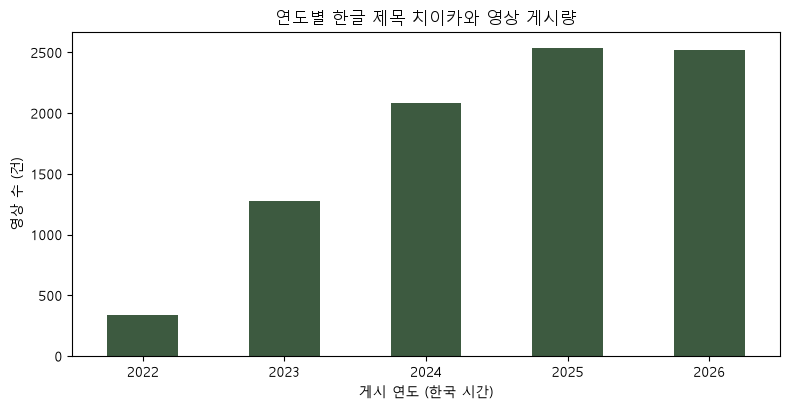

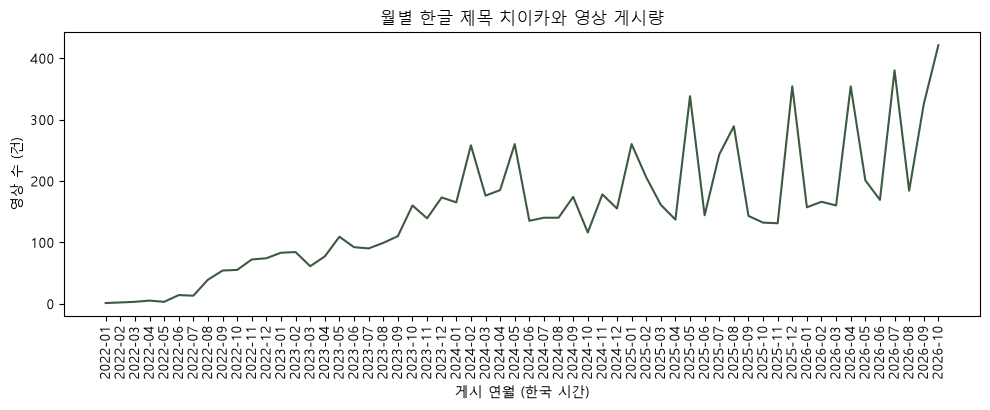

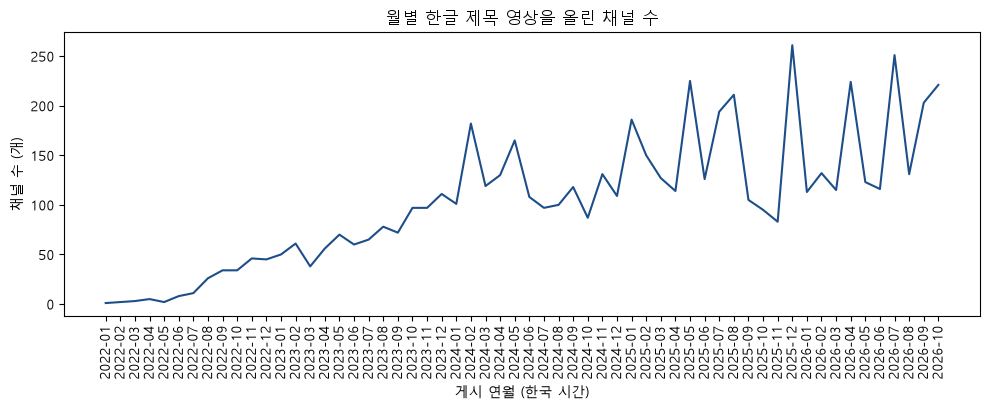

In [11]:
yearly_all = df.groupby("year").size().rename("확정 제외 반영 전체")
yearly_kr = df_kr.groupby("year").size().rename("한글 제목")
yearly = pd.concat([yearly_all, yearly_kr], axis=1).fillna(0).astype(int)
yearly["한글 제목 비율"] = (yearly["한글 제목"] / yearly["확정 제외 반영 전체"]).round(3)
print(yearly)

monthly = df_kr.groupby("year_month").agg(영상수=("video_id", "size"), 활동채널수=("channel_id", "nunique"))
print("\n월별 앞 3개월")
print(monthly.head(3))
print("월별 마지막 3개월")
print(monthly.tail(3))

yearly_channels = df_kr.groupby("year")["channel_id"].nunique().rename("생산 채널 수")
print("\n연도별 생산 채널 수")
print(yearly_channels.to_string())

max_2026 = df_kr.loc[df_kr["year"] == 2026, "publish_at_kst"].max()
print("\n2026년 한글 제목 영상의 마지막 게시 시각", max_2026)

fig, ax = plt.subplots(figsize=(8, 4.2))
yearly["한글 제목"].plot(kind="bar", ax=ax, color="#3d5a40")
ax.set_title("연도별 한글 제목 치이카와 영상 게시량")
ax.set_xlabel("게시 연도 (한국 시간)")
ax.set_ylabel("영상 수 (건)")
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.legend().remove()
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(monthly.index, monthly["영상수"], color="#3d5a40", label="영상 수")
ax.set_title("월별 한글 제목 치이카와 영상 게시량")
ax.set_xlabel("게시 연월 (한국 시간)")
ax.set_ylabel("영상 수 (건)")
ax.tick_params(axis="x", labelrotation=90)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(monthly.index, monthly["활동채널수"], color="#1d4e89", label="활동 채널 수")
ax.set_title("월별 한글 제목 영상을 올린 채널 수")
ax.set_xlabel("게시 연월 (한국 시간)")
ax.set_ylabel("채널 수 (개)")
ax.tick_params(axis="x", labelrotation=90)
fig.tight_layout()
plt.show()

## 분석 2. 캐릭터별 콘텐츠 반응

질문: 어떤 캐릭터 이름이 들어간 영상에서 반응이 상대적으로 높은가?

집계 단위는 영상-캐릭터 언급이다. 한 영상에 캐릭터가 여러 명이면 각 행에 모두 들어간다. 캐릭터별 영상 수를 더하면 고유 영상 수보다 커진다. 언급량을 선호도로 읽지 않는다. 텍스트는 `search_text`다.

           언급영상수   조회수_중앙값  좋아요율_중앙값  댓글률_중앙값  참여율_중앙값  참여율_계산가능
character                                                       
하치와레        1346    4355.5     1.580    0.050    1.666      1252
우사기         1142    4123.5     1.520    0.042    1.616      1067
모몽가          378    5133.5     1.537    0.039    1.693       356
쿠리만쥬         233    3178.0     1.521    0.047    1.634       222
랏코           211    3015.0     1.565    0.043    1.694       198
시사           119   11133.0     1.451    0.044    1.593       110
카니            54    3688.5     1.035    0.080    1.166        49
아노코           32   22545.0     1.330    0.031    1.386        32
파자마파티즈        19   76091.0     1.462    0.045    1.471        15
데카츠요          11  432077.0     1.091    0.034    1.131        11
갑옷씨            7    1565.0     1.587    0.190    1.619         5

특정 캐릭터 언급이 없는 영상 6765
작품명 치이카와 포함 8619 / 먼작귀 2978


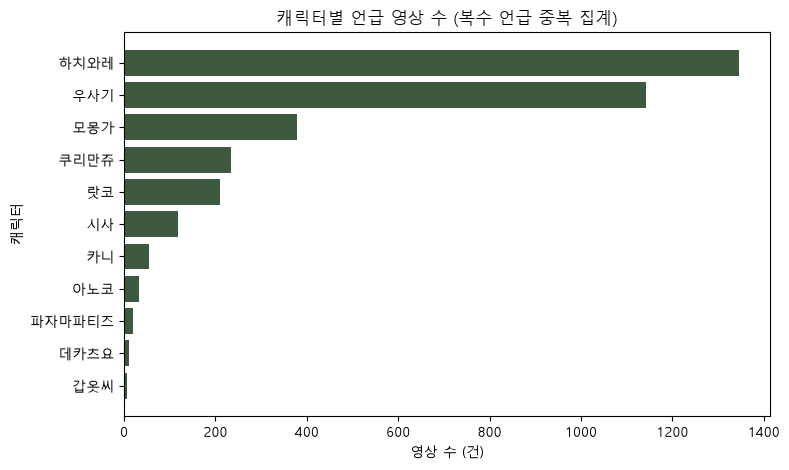

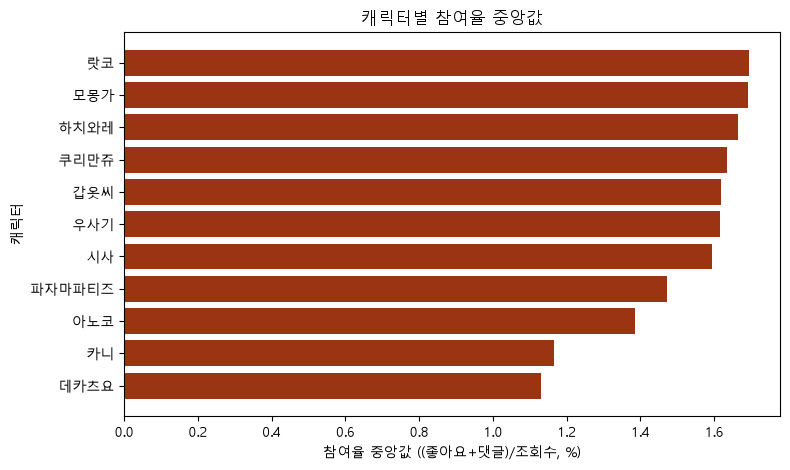

In [12]:
char_frames = []
for name, _ in CHARACTER_RULES:
    part = df_kr.loc[df_kr[f"char_{name}"], ["video_id", "view_count", "like_rate", "comment_rate", "engagement_rate"]].copy()
    part["character"] = name
    char_frames.append(part)
char_long = pd.concat(char_frames, ignore_index=True)
char_summary = char_long.groupby("character").agg(
    언급영상수=("video_id", "size"),
    조회수_중앙값=("view_count", "median"),
    좋아요율_중앙값=("like_rate", "median"),
    댓글률_중앙값=("comment_rate", "median"),
    참여율_중앙값=("engagement_rate", "median"),
    참여율_계산가능=("engagement_rate", "count"),
).sort_values("언급영상수", ascending=False).round(3)
print(char_summary.to_string())
print("\n특정 캐릭터 언급이 없는 영상", int(df_kr["character"].isna().sum()))
print("작품명 치이카와 포함", int(df_kr["series_치이카와"].sum()), "/ 먼작귀", int(df_kr["series_먼작귀"].sum()))

fig, ax = plt.subplots(figsize=(8, 4.8))
plot_df = char_summary.sort_values("언급영상수", ascending=True)
ax.barh(plot_df.index, plot_df["언급영상수"], color="#3d5a40")
ax.set_title("캐릭터별 언급 영상 수 (복수 언급 중복 집계)")
ax.set_xlabel("영상 수 (건)")
ax.set_ylabel("캐릭터")
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4.8))
plot_df = char_summary.sort_values("참여율_중앙값", ascending=True)
ax.barh(plot_df.index, plot_df["참여율_중앙값"], color="#9a3412")
ax.set_title("캐릭터별 참여율 중앙값")
ax.set_xlabel("참여율 중앙값 ((좋아요+댓글)/조회수, %)")
ax.set_ylabel("캐릭터")
fig.tight_layout()
plt.show()

## 분석 3. 채널 구조

질문: 영상이 소수 채널에 몰려 있는가, 여러 채널에서 만들어지는가?

구독자 수는 없다. 채널 규모를 통제한 영향력은 계산하지 않는다.

여기서 연도별 채널 수는 채널을 만든 해가 아니다. 이 검색 표본 안에서 그 채널의 한글 제목 영상이 처음 나온 해다.

고유 채널 수 4165
채널당 게시 수 중앙값 1.0 / 평균 2.1
영상 1개만 올린 채널 비율 0.724
조회수 상위 10채널의 조회수 비중 0.45
조회수 상위 10채널의 영상 수 비중 0.054
  channel  게시수       누적조회수
   AniBox  383 176401890.0
     성우전쟁   18  26081092.0
   오늘은뭐볼까   18  17828821.0
      마금이   12  16155403.0
      C급쇼   10  15696541.0
       조이    6  15292461.0
      쇼도독    4  14645348.0
미슐랭드라마가이드   10  13510319.0
     박노강이   14  13345604.0
    liaaa    1  13171481.0

연도별 수집 표본 내 첫 등장 채널 수
year
2022     155
2023     556
2024     947
2025    1414
2026    1093


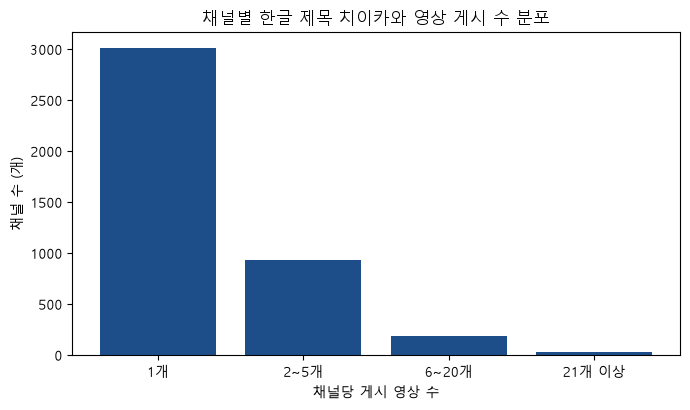

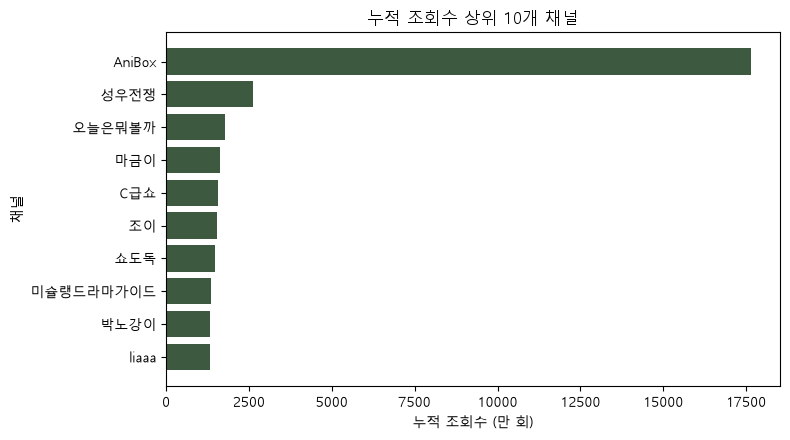

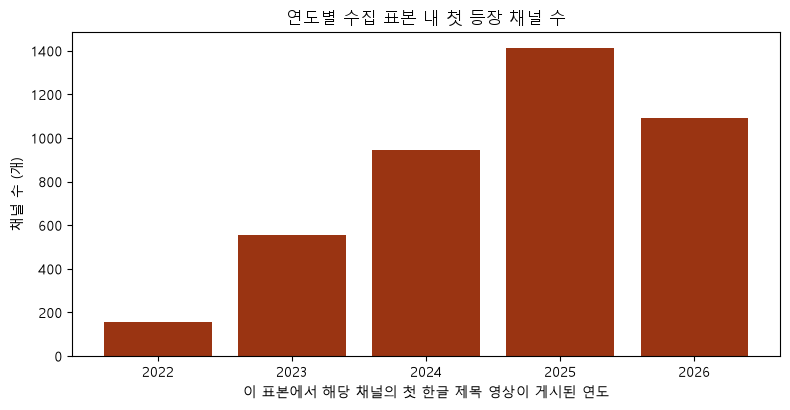

In [13]:
channel_stats = df_kr.groupby(["channel_id", "channel"]).agg(
    게시수=("video_id", "size"),
    누적조회수=("view_count", "sum"),
).reset_index()
n_channels = channel_stats["channel_id"].nunique()
n_videos = len(df_kr)
total_views = df_kr["view_count"].sum()

top10 = channel_stats.sort_values("누적조회수", ascending=False).head(10)
top10_view_share = top10["누적조회수"].sum() / total_views
top10_video_share = top10["게시수"].sum() / n_videos
one_video_share = (channel_stats["게시수"] == 1).mean()

print("고유 채널 수", n_channels)
print("채널당 게시 수 중앙값", channel_stats["게시수"].median(), "/ 평균", round(channel_stats["게시수"].mean(), 2))
print("영상 1개만 올린 채널 비율", round(one_video_share, 3))
print("조회수 상위 10채널의 조회수 비중", round(top10_view_share, 3))
print("조회수 상위 10채널의 영상 수 비중", round(top10_video_share, 3))
print(top10[["channel", "게시수", "누적조회수"]].to_string(index=False))

first_year = df_kr.groupby("channel_id")["year"].min()
first_seen_channels = first_year.value_counts().sort_index().rename("수집 표본 내 첫 등장 채널 수")
print("\n연도별 수집 표본 내 첫 등장 채널 수")
print(first_seen_channels.to_string())

bins = pd.cut(
    channel_stats["게시수"],
    bins=[0, 1, 5, 20, channel_stats["게시수"].max()],
    labels=["1개", "2~5개", "6~20개", "21개 이상"],
)
dist = bins.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.bar(dist.index.astype(str), dist.values, color="#1d4e89")
ax.set_title("채널별 한글 제목 치이카와 영상 게시 수 분포")
ax.set_xlabel("채널당 게시 영상 수")
ax.set_ylabel("채널 수 (개)")
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4.5))
top_plot = top10.sort_values("누적조회수", ascending=True)
ax.barh(top_plot["channel"], top_plot["누적조회수"] / 10000, color="#3d5a40")
ax.set_title("누적 조회수 상위 10개 채널")
ax.set_xlabel("누적 조회수 (만 회)")
ax.set_ylabel("채널")
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(first_seen_channels.index.astype(str), first_seen_channels.values, color="#9a3412")
ax.set_title("연도별 수집 표본 내 첫 등장 채널 수")
ax.set_xlabel("이 표본에서 해당 채널의 첫 한글 제목 영상이 게시된 연도")
ax.set_ylabel("채널 수 (개)")
fig.tight_layout()
plt.show()

## 분석 4. 9종 소비·콘텐츠 유형의 다중 라벨 분류

각 유형은 제목만 보고 따로 판정한다. 우선순위로 하나를 고르지 않는다. 한 영상은 0개에서 9개까지 라벨을 가질 수 있다. 열 이름은 `v2_type_*`, `v2_content_labels`, `v2_label_count`다.

유형별 영상 수는 그 유형에 해당하는 고유 영상 수다. 같은 제목에 `키링`과 `굿즈`가 같이 있어도 굿즈 유형은 1편이다. 비율의 분모는 한글 제목 영상 전체다. 라벨이 겹치므로 비율을 더하면 100%를 넘을 수 있다. 이 비율은 배타적인 구성비가 아니다.

제목에 단어가 있다고 해서 그 영상을 본 사람이 구매하거나, 방문하거나, 작품 회차를 봤다는 뜻은 아니다.

경계 규칙은 다음과 같다.

- `인형계`는 보유 후 놀이의 근거다. `인형계` 안의 `인형`만으로 굿즈를 추가하지 않는다.
- 같은 제목에 굿즈 키워드가 따로 있으면 굿즈와 보유 후 놀이를 같이 준다.
- `인형뽑기` 안의 `뽑기`만으로 가챠·쿠지를 추가하지 않는다. 제목 전체를 가챠에서 빼는 방식은 쓰지 않는다. 같은 제목에 `가챠`, `쿠지`, `제일복권`, `복권`, `랜덤깡`, 또는 `인형뽑기`와 별개인 `뽑기`가 있으면 두 라벨을 같이 준다.
- 기본 굿즈의 `인형(?!계)`는 `인형뽑기`에도 맞는다. 기본 결과는 그대로 두고, `인형뽑기`의 `인형`을 굿즈 근거에서 뺀 대안 건수를 따로 낸다.
- `포카`는 `포카포장`에도 맞는다.
- `빵`, `애니`처럼 짧은 단어는 제목 표본으로 오탐을 본다. 기본 사전은 요청된 단어를 유지한다.


In [14]:
V2_TYPES = [
    "굿즈", "포토카드", "가챠·쿠지", "인형뽑기", "애니메이션·영화 관련 콘텐츠",
    "팝업·카페", "식음", "콜라보", "보유 후 놀이",
]

V2_KEYWORDS = {
    "굿즈": [
        ("인형(인형계 제외)", r"인형(?!계)"),
        ("키링", r"키링"),
        ("피규어", r"피규어"),
        ("스티커", r"스티커"),
        ("굿즈", r"굿즈"),
        ("언박싱", r"언박싱"),
        ("하울", r"하울"),
        ("개봉", r"개봉"),
        ("마스코트", r"마스코트"),
        ("아크릴", r"아크릴"),
        ("파우치", r"파우치"),
        ("쿠션", r"쿠션"),
    ],
    "포토카드": [("포카", r"포카")],
    "가챠·쿠지": [
        ("가챠", r"가챠"),
        ("랜덤깡", r"랜덤깡"),
        ("쿠지", r"쿠지"),
        ("제일복권", r"제일복권"),
        ("복권", r"복권"),
        ("뽑기(인형뽑기 제외)", r"(?<!인형)뽑기"),
    ],
    "인형뽑기": [("인형뽑기", r"인형뽑기")],
    "애니메이션·영화 관련 콘텐츠": [
        ("전편공개", r"전편공개"),
        ("최신화", r"최신화"),
        ("애니", r"애니"),
        ("극장판", r"극장판"),
        ("영화", r"영화"),
    ],
    "팝업·카페": [("팝업", r"팝업"), ("카페", r"카페")],
    "식음": [
        ("빵", r"빵"),
        ("도시락", r"도시락"),
        ("케이크", r"케이크"),
        ("과자", r"과자"),
        ("초콜릿", r"초콜릿"),
    ],
    "콜라보": [("콜라보", r"콜라보")],
    "보유 후 놀이": [
        ("인형계", r"인형계"),
        ("더빙", r"더빙"),
        ("팬아트", r"팬아트"),
        ("그리기", r"그리기"),
        ("만들기", r"만들기"),
    ],
}

GOODS_ALT_KEYWORDS = [
    ("인형(인형계·인형뽑기 제외)", r"인형(?!계|뽑기)"),
] + [item for item in V2_KEYWORDS["굿즈"] if item[0] != "인형(인형계 제외)"]

titles = df_kr["title"].fillna("")

def matched_names(text, specs):
    return [name for name, pattern in specs if re.search(pattern, text)]

keyword_rows = []
for label, specs in V2_KEYWORDS.items():
    found = titles.map(lambda text, specs=specs: matched_names(text, specs))
    df_kr[f"v2_kw_{label}"] = found.map(lambda names: "|".join(names) if names else pd.NA)
    df_kr[f"v2_type_{label}"] = found.map(bool)
    for name, pattern in specs:
        hit = titles.map(lambda text, pattern=pattern: bool(re.search(pattern, text)))
        keyword_rows.append({
            "유형": label,
            "키워드": name,
            "정규식": pattern,
            "언급 영상 수": int(hit.sum()),
            "언급 영상 비율": round(float(hit.sum()) / N_KR, 4),
        })

goods_alt = titles.map(lambda text: bool(matched_names(text, GOODS_ALT_KEYWORDS)))
df_kr["v2_type_굿즈_인형뽑기문구제외"] = goods_alt

v2_flag_cols = [f"v2_type_{label}" for label in V2_TYPES]
df_kr["v2_label_count"] = df_kr[v2_flag_cols].sum(axis=1).astype(int)
df_kr["v2_content_labels"] = df_kr.apply(
    lambda row: "|".join([label for label in V2_TYPES if row[f"v2_type_{label}"]]) or pd.NA,
    axis=1,
)

keyword_mention = pd.DataFrame(keyword_rows)
print("사전 키워드별 고유 영상 수. 유형 OR 집계와 다르다")
print(keyword_mention.to_string(index=False))
print("\n굿즈 기본", int(df_kr["v2_type_굿즈"].sum()))
print("굿즈 대안: 인형뽑기의 인형을 근거에서 제외", int(df_kr["v2_type_굿즈_인형뽑기문구제외"].sum()))
print(
    "기본에만 있고 대안에 없는 영상",
    int((df_kr["v2_type_굿즈"] & ~df_kr["v2_type_굿즈_인형뽑기문구제외"]).sum()),
)

사전 키워드별 고유 영상 수. 유형 OR 집계와 다르다
             유형         키워드       정규식  언급 영상 수  언급 영상 비율
             굿즈  인형(인형계 제외)   인형(?!계)      654    0.0748
             굿즈          키링        키링      208    0.0238
             굿즈         피규어       피규어      316    0.0361
             굿즈         스티커       스티커      145    0.0166
             굿즈          굿즈        굿즈      413    0.0472
             굿즈         언박싱       언박싱      296    0.0338
             굿즈          하울        하울       90    0.0103
             굿즈          개봉        개봉       80    0.0091
             굿즈        마스코트      마스코트       53    0.0061
             굿즈         아크릴       아크릴       49    0.0056
             굿즈         파우치       파우치       35    0.0040
             굿즈          쿠션        쿠션       33    0.0038
           포토카드          포카        포카      239    0.0273
          가챠·쿠지          가챠        가챠      519    0.0593
          가챠·쿠지         랜덤깡       랜덤깡      304    0.0347
          가챠·쿠지          쿠지        쿠지      116    0.0133


## 짧은 키워드와 경계 사례

`빵`과 `애니`는 기본 사전에 그대로 둔다. 아래는 그 단어가 들어간 제목 표본이다. 사전이 바뀌면 기본 건수와 달라진 건수를 같이 적는다. 이번 실행에서 사전을 바꾸면 그 셀의 출력에 변경 전후가 남는다.

In [15]:
def show_titles(mask, heading, n=12):
    sample = df_kr.loc[mask, "title"].head(n)
    print(f"\n{heading} {int(mask.sum())}편 중 {len(sample)}개")
    for title in sample:
        print("-", title)

show_titles(titles.str.contains(r"빵", regex=True), "빵")
show_titles(titles.str.contains(r"애니", regex=True), "애니")
show_titles(titles.str.contains(r"포카포장", regex=True), "포카포장")
show_titles(titles.str.contains(r"인형계", regex=True) & df_kr["v2_type_굿즈"], "인형계이면서 굿즈 키워드가 따로 있는 제목")
show_titles(titles.str.contains(r"인형계", regex=True) & ~df_kr["v2_type_굿즈"], "인형계만 있고 굿즈는 아닌 제목")
show_titles(
    titles.str.contains(r"인형뽑기", regex=True) & ~titles.str.contains(r"가챠|랜덤깡|쿠지|제일복권|복권|(?<!인형)뽑기", regex=True),
    "인형뽑기만 있고 가챠·쿠지 근거는 없는 제목",
)
show_titles(
    titles.str.contains(r"인형뽑기", regex=True) & df_kr["v2_type_가챠·쿠지"],
    "인형뽑기와 가챠·쿠지가 함께 있는 제목",
)
show_titles(titles.str.contains(r"(?<!인형)뽑기", regex=True), "인형뽑기와 별도인 뽑기")

# 빵: 호빵맨만 맞는 제목은 식음 오탐 후보다. 기본 사전은 유지하고 대안 건수만 비교한다.
bread_base = titles.str.contains(r"빵", regex=True)
bread_alt = titles.str.contains(r"(?<!호)빵", regex=True)
print("\n빵 기본", int(bread_base.sum()), "/ (?<!호)빵 대안", int(bread_alt.sum()), "/ 차이", int((bread_base & ~bread_alt).sum()))
print("땡글빵 포함", int(titles.str.contains("땡글빵", regex=False).sum()))
print("애니 기본", int(titles.str.contains("애니", regex=False).sum()), "/ 애니메이트", int(titles.str.contains("애니메이트", regex=False).sum()))
print("사전은 바꾸지 않았다. 호빵 제외와 애니메이트 제외는 대안 비교만 한다.")


빵 75편 중 12개
- 치이카와 붕어....?빵을 제가 새벽 5시부터 일어난 사람 나야나😄
- 먼작귀 치이카와 메론빵, 치이카와 부르부르즈 5종 랜덤 박스깡
- 오타쿠브이로그 | 치이카와인형 또 샀어.. | 오타쿠 | 다꾸템 | 호빵맨가챠 | 스파이패밀리 |택배깡
- 오타쿠브이로그 | 택배깡 | 다꾸템 | 가챠샵 | 치이카와가챠 | 치이카와인형 드디어 득템! |스파이패밀리 |호빵맨가챠
- 🎀[오타쿠브이로그] 귀여운건 뭐든 매입하는 사람 | 치이카와 랜덤깡 | 케로로빵 산리오 | (여자)아이들 Nxde 앨범구매 | 언박싱 택배깡 프박 | 인형옷 | Otaku Vlog
- 🎀[오타쿠 브이로그] 드디어 매지컬 치이카와가..💕| 산리오 메로쿠로, 돌리믹스 콜라보 | 네가죽어 띠부 | 케로로빵 다꾸스티커 | 언박싱 랜덤깡 택배깡 | Otaku Vlog
- 일본에서 산 맛있는 치이카와 빵에 들어있던 의문의 물건 언박싱.. #shorts
- 오타쿠 투어 in 신도림!! / 메나미죠죠 조이하비 땡글빵글 치이카와 넨도로이드 피규어 신도림 키덜트샵 투어 오타쿠브이로그
- 치이카와 문어빵맛 과자,치이카와카레!!
- 오타쿠 브이로그•Otaku Vlog/메나미죠죠 방문기💗/치이카와 대량 매입하기🎁/땡글빵글도 다녀왔다!/Chiikawa
- 치이카와•산리오 덕후 필수코스! 랜덤가챠부터 신상까지💸신도림 메나미죠죠•땡글빵글
- 귀요미 카레가 잔뜩 (치이카와/포켓몬/귀멸의칼날/짱구/호빵맨)

애니 48편 중 12개
- Fukuoka vlog | 나홀로 후쿠오카 여행 | 세미오타쿠(?)의 애니메이트 & 치이카와샵 방문기🤩✨ | 돈키호테 & 일본 마트 쇼핑
- 오타쿠 투어 in 홍대!! / 먼작귀팝업 애니메이트 치이카와 피규어 덕질브이로그 오타쿠브이로그 홍대 굿즈샵 투어
- 치이카와 애니화 따라해보기
- 애니 굿즈샵 ♡ 치이카와 인형 ♡ 스파이패밀리 뱃지 ♡
- 일본vlogㅣ오늘은 이케부쿠로⭐️ 애니메이트 점페 & 치이카와 팝업스토어 구경하고 치이카와 북마크 박스깡 하는 오타쿠 브이로그
- 

## 9종별 규모와 이용자 반응

비율의 분모는 전체 분석 대상 영상 수다. 한 영상에 여러 유형이 붙으므로 유형별 비율의 합은 100%를 넘을 수 있다.

조회수 평균은 일부 상위 영상에 영향을 받으므로 중앙값을 함께 본다. 좋아요·댓글이 결측이면 참여율은 계산하지 않는다. 반응 차이를 인기의 원인으로 단정하지 않는다.

             유형  영상 수  전체 대비 비율     조회수 평균  조회수 중앙값  좋아요율 중앙값  좋아요율 계산 가능  댓글률 중앙값  댓글률 계산 가능  참여율 중앙값  참여율 계산 가능  길이초 중앙값  60초 이하 비율  60초 이하 영상 수
             굿즈  1935     0.221  13697.309   1407.0     1.571        1785    0.077       1815    1.714       1681     56.0      0.590         1142
           포토카드   239     0.027   8395.377   1011.0     3.092         191    0.325        191    3.503        149     45.0      0.879          210
          가챠·쿠지  1120     0.128  16972.361   1697.0     1.447        1017    0.070       1086    1.633        996     58.0      0.571          639
           인형뽑기   246     0.028   7397.911   2406.0     0.917         238    0.044        242    1.053        237     42.0      0.707          174
애니메이션·영화 관련 콘텐츠   456     0.052 455601.621 427685.5     1.122         448    0.038        453    1.163        445     91.0      0.252          115
          팝업·카페   247     0.028   7943.117   1883.0     1.476         220    0.135        242    1.672        215    5

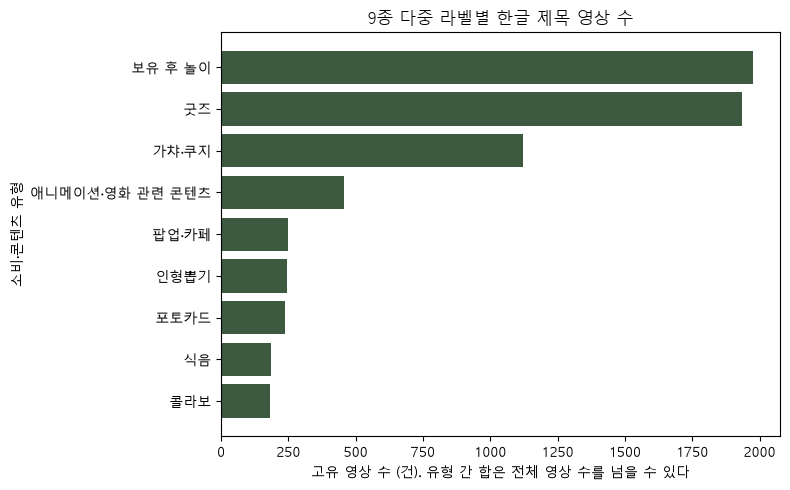

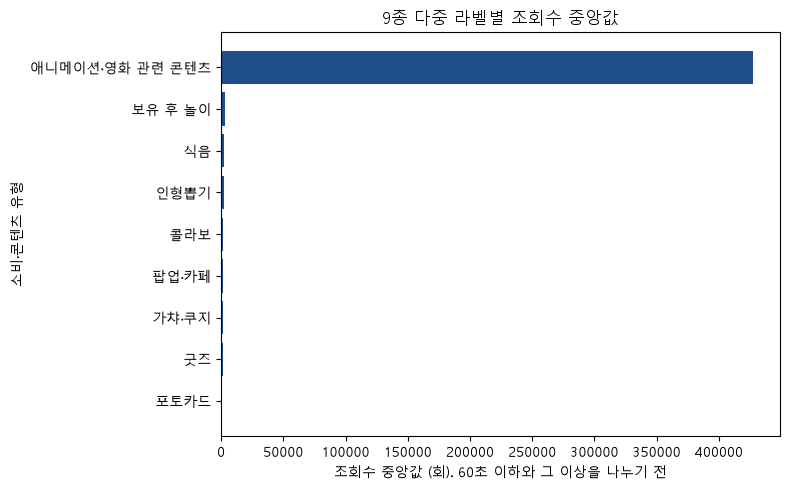

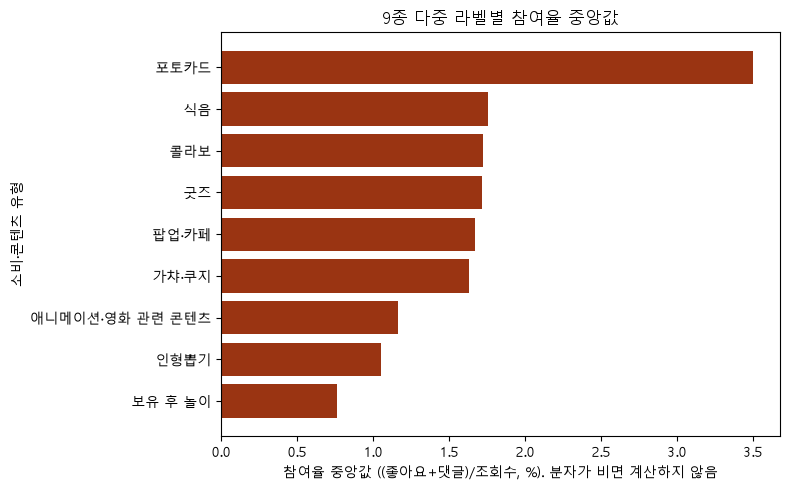

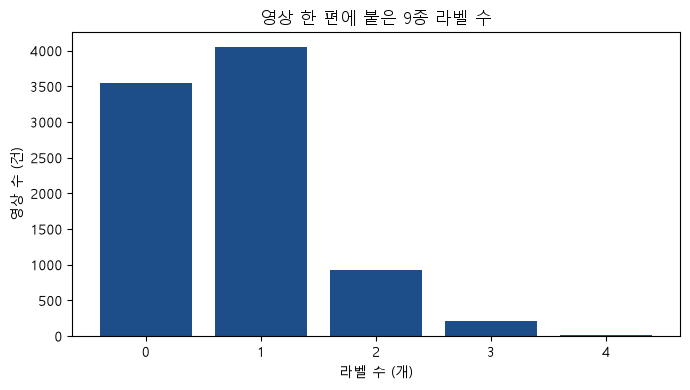

In [16]:
def mask_summary(frame):
    return {
        "영상 수": len(frame),
        "전체 대비 비율": round(len(frame) / N_KR, 4),
        "조회수 평균": frame["view_count"].mean(),
        "조회수 중앙값": frame["view_count"].median(),
        "좋아요율 중앙값": frame["like_rate"].median(),
        "좋아요율 계산 가능": int(frame["like_rate"].notna().sum()),
        "댓글률 중앙값": frame["comment_rate"].median(),
        "댓글률 계산 가능": int(frame["comment_rate"].notna().sum()),
        "참여율 중앙값": frame["engagement_rate"].median(),
        "참여율 계산 가능": int(frame["engagement_rate"].notna().sum()),
        "길이초 중앙값": frame["duration_sec"].median(),
        "60초 이하 비율": frame["is_short_60"].mean(),
        "60초 이하 영상 수": int(frame["is_short_60"].fillna(False).sum()),
    }

v2_rows = []
for label in V2_TYPES:
    part = df_kr.loc[df_kr[f"v2_type_{label}"]]
    row = {"유형": label}
    row.update(mask_summary(part))
    v2_rows.append(row)
v2_summary = pd.DataFrame(v2_rows).round(3)
print(v2_summary.to_string(index=False))

unlabeled_n = int((df_kr["v2_label_count"] == 0).sum())
print("\n9종 미분류", unlabeled_n, f"({unlabeled_n / N_KR:.3f})")
print("영상당 라벨 수")
print(df_kr["v2_label_count"].value_counts().sort_index().to_string())

fig, ax = plt.subplots(figsize=(8, 5))
plot_df = v2_summary.sort_values("영상 수", ascending=True)
ax.barh(plot_df["유형"], plot_df["영상 수"], color="#3d5a40")
ax.set_title("9종 다중 라벨별 한글 제목 영상 수")
ax.set_xlabel("고유 영상 수 (건). 유형 간 합은 전체 영상 수를 넘을 수 있다")
ax.set_ylabel("소비·콘텐츠 유형")
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
plot_df = v2_summary.sort_values("조회수 중앙값", ascending=True)
ax.barh(plot_df["유형"], plot_df["조회수 중앙값"], color="#1d4e89")
ax.set_title("9종 다중 라벨별 조회수 중앙값")
ax.set_xlabel("조회수 중앙값 (회). 60초 이하와 그 이상을 나누기 전")
ax.set_ylabel("소비·콘텐츠 유형")
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
plot_df = v2_summary.sort_values("참여율 중앙값", ascending=True)
ax.barh(plot_df["유형"], plot_df["참여율 중앙값"], color="#9a3412")
ax.set_title("9종 다중 라벨별 참여율 중앙값")
ax.set_xlabel("참여율 중앙값 ((좋아요+댓글)/조회수, %). 분자가 비면 계산하지 않음")
ax.set_ylabel("소비·콘텐츠 유형")
fig.tight_layout()
plt.show()

label_dist = df_kr["v2_label_count"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(label_dist.index.astype(str), label_dist.values, color="#1d4e89")
ax.set_title("영상 한 편에 붙은 9종 라벨 수")
ax.set_xlabel("라벨 수 (개)")
ax.set_ylabel("영상 수 (건)")
fig.tight_layout()
plt.show()

             유형  60초 이하 영상 수  60초 이하 조회수 중앙값  60초 초과 영상 수  60초 초과 조회수 중앙값  길이초 중앙값
             굿즈         1142          1387.0          793          1458.0     56.0
           포토카드          210          1151.5           29           755.0     45.0
          가챠·쿠지          639          1447.0          481          2181.0     58.0
           인형뽑기          174          2257.0           72          3310.5     42.0
애니메이션·영화 관련 콘텐츠          115         13703.0          341        499015.0     91.0
          팝업·카페           75          2433.0          172          1624.5    582.0
             식음          116          2680.0           68          2447.5     52.0
            콜라보           99          2103.0           81          1574.0     58.0
        보유 후 놀이         1821          3995.0          156           627.0     35.0
60초 이하는 길이 기준이다. 유튜브 쇼츠 공식 분류가 아니다.


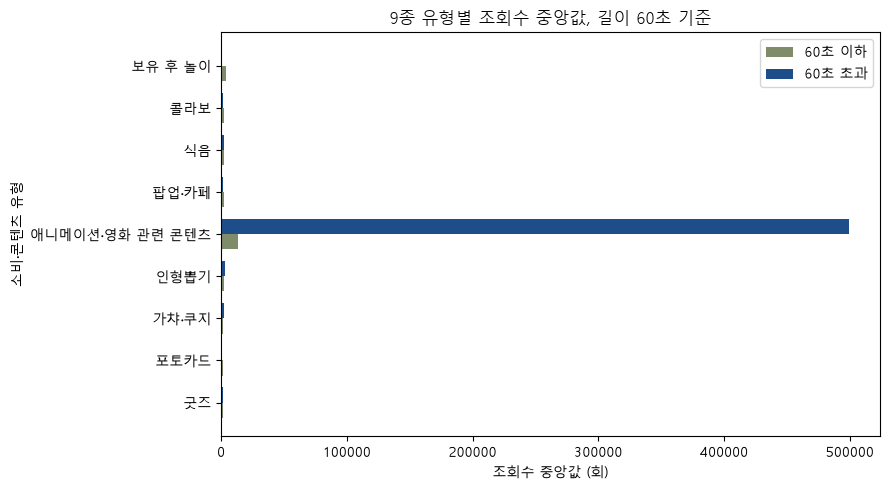

In [17]:
length_rows = []
for label in V2_TYPES:
    part = df_kr.loc[df_kr[f"v2_type_{label}"]]
    short = part.loc[part["is_short_60"] == True]
    long = part.loc[part["is_short_60"] == False]
    length_rows.append({
        "유형": label,
        "60초 이하 영상 수": len(short),
        "60초 이하 조회수 중앙값": short["view_count"].median(),
        "60초 초과 영상 수": len(long),
        "60초 초과 조회수 중앙값": long["view_count"].median(),
        "길이초 중앙값": part["duration_sec"].median(),
    })
length_summary = pd.DataFrame(length_rows).round(1)
print(length_summary.to_string(index=False))
print("60초 이하는 길이 기준이다. 유튜브 쇼츠 공식 분류가 아니다.")

fig, ax = plt.subplots(figsize=(9, 5))
y = np.arange(len(length_summary))
ax.barh(y - 0.18, length_summary["60초 이하 조회수 중앙값"], height=0.36, color="#7f8c6a", label="60초 이하")
ax.barh(y + 0.18, length_summary["60초 초과 조회수 중앙값"], height=0.36, color="#1d4e89", label="60초 초과")
ax.set_yticks(y)
ax.set_yticklabels(length_summary["유형"])
ax.set_xlabel("조회수 중앙값 (회)")
ax.set_ylabel("소비·콘텐츠 유형")
ax.set_title("9종 유형별 조회수 중앙값, 길이 60초 기준")
ax.legend()
fig.tight_layout()
plt.show()

연도별 유형 영상 수
        굿즈  포토카드  가챠·쿠지  인형뽑기  애니메이션·영화 관련 콘텐츠  팝업·카페  식음  콜라보  보유 후 놀이
게시 연도                                                                  
2022   148     0     93     1                3     28  13   26        4
2023   411    86    256    11               76     49  36   32       88
2024   578    75    326    72               56     35  65   44      351
2025   400    67    222    77               70     29  42   43     1070
2026   398    11    223    85              251    106  28   35      464

연도별 유형 비율. 분모는 그 해의 한글 제목 영상 수
          굿즈    포토카드   가챠·쿠지    인형뽑기  애니메이션·영화 관련 콘텐츠   팝업·카페      식음     콜라보  보유 후 놀이
2022  0.4418  0.0000  0.2776  0.0030           0.0090  0.0836  0.0388  0.0776   0.0119
2023  0.3218  0.0673  0.2005  0.0086           0.0595  0.0384  0.0282  0.0251   0.0689
2024  0.2776  0.0360  0.1566  0.0346           0.0269  0.0168  0.0312  0.0211   0.1686
2025  0.1576  0.0264  0.0875  0.0303           0.0276  0.0114  0.0165  0.0169   0.4216
2026  0.1581  0.0

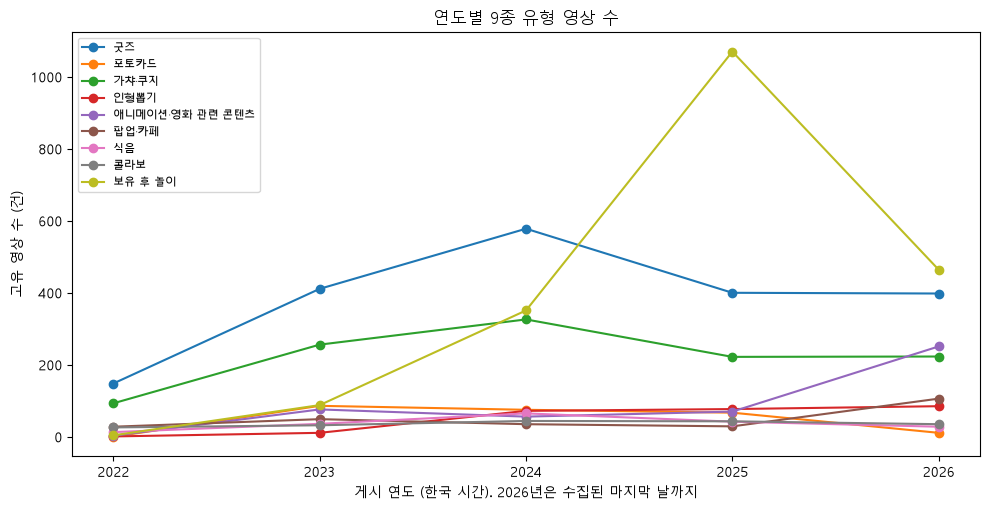


월별 유형 영상 수, 앞 2개월
         굿즈  포토카드  가챠·쿠지  인형뽑기  애니메이션·영화 관련 콘텐츠  팝업·카페  식음  콜라보  보유 후 놀이
2022-01   1     0      0     0                0      0   0    0        0
2022-02   1     0      0     0                0      0   0    0        0
월별 유형 영상 수, 마지막 2개월
         굿즈  포토카드  가챠·쿠지  인형뽑기  애니메이션·영화 관련 콘텐츠  팝업·카페  식음  콜라보  보유 후 놀이
2026-09  59     1     19     2              104      5   3    3       21
2026-10  15     0      5     1               64      0   5    1       23


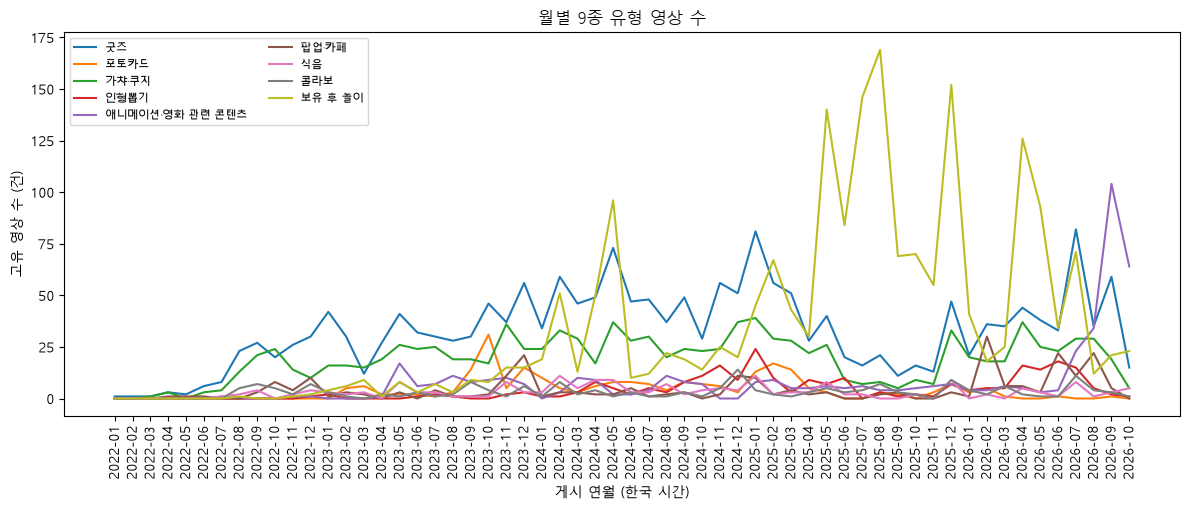


키워드별 연도 언급 영상 수
             유형         키워드  게시 연도  언급 영상 수  그 해 영상 대비 비율
             굿즈  인형(인형계 제외)   2022       38        0.1134
             굿즈  인형(인형계 제외)   2023       90        0.0705
             굿즈  인형(인형계 제외)   2024      216        0.1037
             굿즈  인형(인형계 제외)   2025      198        0.0780
             굿즈  인형(인형계 제외)   2026      112        0.0445
             굿즈          키링   2022       12        0.0358
             굿즈          키링   2023       48        0.0376
             굿즈          키링   2024       67        0.0322
             굿즈          키링   2025       43        0.0169
             굿즈          키링   2026       38        0.0151
             굿즈         피규어   2022       19        0.0567
             굿즈         피규어   2023       65        0.0509
             굿즈         피규어   2024      110        0.0528
             굿즈         피규어   2025       51        0.0201
             굿즈         피규어   2026       71        0.0282
             굿즈         스티커   2022       19        0.05

In [18]:
years = sorted(df_kr["year"].dropna().unique())
year_total = df_kr.groupby("year").size()
yearly_type_count = pd.DataFrame(index=years)
yearly_type_share = pd.DataFrame(index=years)
for label in V2_TYPES:
    counts = df_kr.loc[df_kr[f"v2_type_{label}"]].groupby("year").size()
    yearly_type_count[label] = counts.reindex(years).fillna(0).astype(int)
    yearly_type_share[label] = (yearly_type_count[label] / year_total.reindex(years)).round(4)
yearly_type_count.index.name = "게시 연도"
print("연도별 유형 영상 수")
print(yearly_type_count.to_string())
print("\n연도별 유형 비율. 분모는 그 해의 한글 제목 영상 수")
print(yearly_type_share.to_string())

fig, ax = plt.subplots(figsize=(10, 5.2))
for label in V2_TYPES:
    ax.plot(yearly_type_count.index.astype(str), yearly_type_count[label], marker="o", label=label)
ax.set_title("연도별 9종 유형 영상 수")
ax.set_xlabel("게시 연도 (한국 시간). 2026년은 수집된 마지막 날까지")
ax.set_ylabel("고유 영상 수 (건)")
ax.legend(fontsize=8, loc="upper left")
fig.tight_layout()
plt.show()

monthly_type = pd.DataFrame(index=sorted(df_kr["year_month"].dropna().unique()))
for label in V2_TYPES:
    counts = df_kr.loc[df_kr[f"v2_type_{label}"]].groupby("year_month").size()
    monthly_type[label] = counts.reindex(monthly_type.index).fillna(0).astype(int)
print("\n월별 유형 영상 수, 앞 2개월")
print(monthly_type.head(2).to_string())
print("월별 유형 영상 수, 마지막 2개월")
print(monthly_type.tail(2).to_string())

fig, ax = plt.subplots(figsize=(12, 5.2))
for label in V2_TYPES:
    ax.plot(monthly_type.index, monthly_type[label], label=label)
ax.set_title("월별 9종 유형 영상 수")
ax.set_xlabel("게시 연월 (한국 시간)")
ax.set_ylabel("고유 영상 수 (건)")
ax.tick_params(axis="x", labelrotation=90)
ax.legend(fontsize=8, ncol=2)
fig.tight_layout()
plt.show()

# 주요 키워드 연도별 고유 영상 수. 신규 시계열이며 Kiwi 결과가 아니다.
keyword_year_rows = []
for label, specs in V2_KEYWORDS.items():
    for name, pattern in specs:
        hit = df_kr.loc[titles.str.contains(pattern, regex=True)]
        by_year = hit.groupby("year").size()
        for year in years:
            keyword_year_rows.append({
                "유형": label,
                "키워드": name,
                "게시 연도": int(year),
                "언급 영상 수": int(by_year.get(year, 0)),
                "그 해 영상 대비 비율": round(int(by_year.get(year, 0)) / int(year_total.loc[year]), 4),
            })
keyword_year = pd.DataFrame(keyword_year_rows)
print("\n키워드별 연도 언급 영상 수")
print(keyword_year.to_string(index=False))

유형 동시 출현 영상 수. 대각선은 그 유형의 영상 수
                   굿즈  포토카드  가챠·쿠지  인형뽑기  애니메이션·영화 관련 콘텐츠  팝업·카페   식음  콜라보  보유 후 놀이
굿즈               1935    29    525   246               52     76   36   76      186
포토카드               29   239      9     0                0      1    3    5       21
가챠·쿠지             525     9   1120   130               22     43   26   29       12
인형뽑기              246     0    130   246                1      3    6    1        3
애니메이션·영화 관련 콘텐츠    52     0     22     1              456      5   11    2        7
팝업·카페              76     1     43     3                5    247    3   15        3
식음                 36     3     26     6               11      3  184    3       30
콜라보                76     5     29     1                2     15    3  180        2
보유 후 놀이           186    21     12     3                7      3   30    2     1977


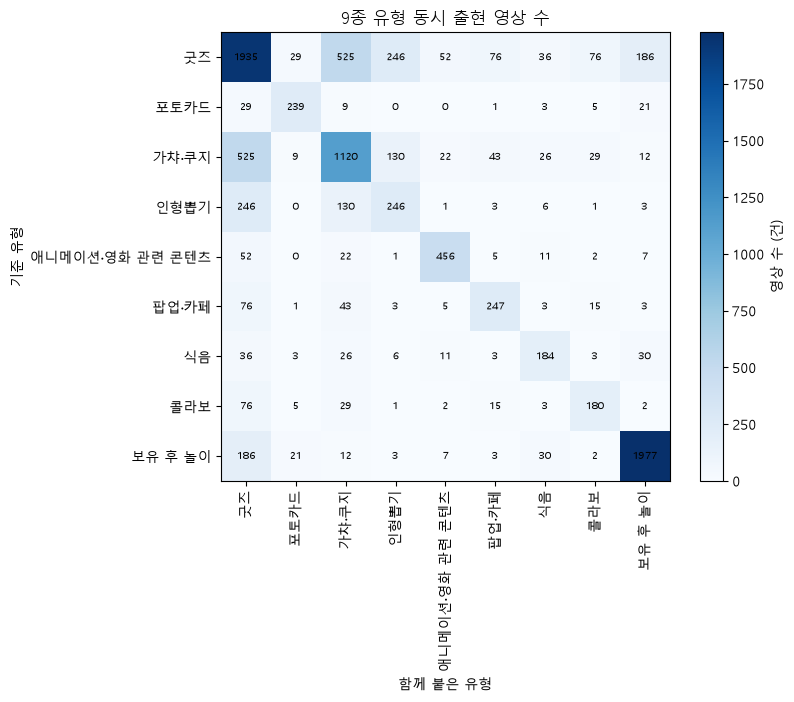

In [19]:
co = pd.DataFrame(0, index=V2_TYPES, columns=V2_TYPES, dtype=int)
for left in V2_TYPES:
    for right in V2_TYPES:
        co.loc[left, right] = int((df_kr[f"v2_type_{left}"] & df_kr[f"v2_type_{right}"]).sum())
print("유형 동시 출현 영상 수. 대각선은 그 유형의 영상 수")
print(co.to_string())

fig, ax = plt.subplots(figsize=(8.5, 7))
image = ax.imshow(co.to_numpy(), cmap="Blues")
ax.set_xticks(range(len(V2_TYPES)))
ax.set_yticks(range(len(V2_TYPES)))
ax.set_xticklabels(V2_TYPES, rotation=90)
ax.set_yticklabels(V2_TYPES)
ax.set_title("9종 유형 동시 출현 영상 수")
ax.set_xlabel("함께 붙은 유형")
ax.set_ylabel("기준 유형")
for i in range(len(V2_TYPES)):
    for j in range(len(V2_TYPES)):
        ax.text(j, i, str(co.iloc[i, j]), ha="center", va="center", fontsize=7)
fig.colorbar(image, ax=ax, label="영상 수 (건)")
fig.tight_layout()
plt.show()

## 2026년은 부분 기간

2026년 수치를 다른 해의 1~12월과 같은 연간 수치로 비교하지 않는다. 아래는 2026년 마지막 게시일의 월·일까지를 매년 같은 기간으로 자른 한글 제목 영상 수다. 이것도 검색 표본 안의 수다.

2026년 마지막 게시일 2026-10-26 19:00:08+09:00 / 비교 구간 월-일 <= (10, 26)
year
2022     183
2023     938
2024    1730
2025    2037
2026    2517


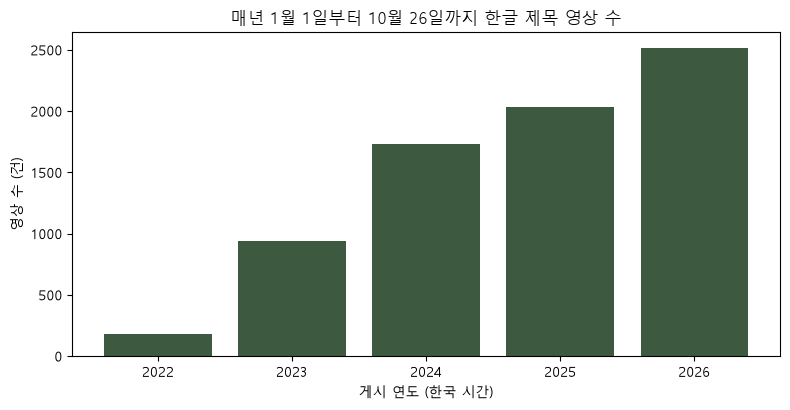

In [20]:
max_2026 = df_kr.loc[df_kr["year"] == 2026, "publish_at_kst"].max()
cutoff = (int(max_2026.month), int(max_2026.day))
same_window = df_kr["publish_at_kst"].map(lambda value: (int(value.month), int(value.day)) <= cutoff)
print("2026년 마지막 게시일", max_2026, "/ 비교 구간 월-일 <=", cutoff)
window_counts = df_kr.loc[same_window].groupby("year").size().rename("같은 월일까지의 한글 제목 영상 수")
print(window_counts.to_string())

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(window_counts.index.astype(str), window_counts.values, color="#3d5a40")
ax.set_title(f"매년 1월 1일부터 {cutoff[0]}월 {cutoff[1]}일까지 한글 제목 영상 수")
ax.set_xlabel("게시 연도 (한국 시간)")
ax.set_ylabel("영상 수 (건)")
fig.tight_layout()
plt.show()

## 해석을 읽는 기준

관찰한 사실과 가설을 구분한다.

관찰한 사실로 말할 수 있는 것

- 검색 결과 중 이름 확인을 통과한 영상, 그중 한글 제목 영상에서 9개 단어 묶음이 각각 몇 편인가.
- 한 제목에 묶음이 몇 개 같이 있는가.
- 길이 60초를 기준으로 나눈 조회수 중앙값과, 결측을 남긴 채 계산한 반응률.

가설이라서 이 노트북만으로 확정하지 않는 것

- 영상 수가 많은 유형이 더 많이 팔린다.
- 조회수 중앙값이 큰 유형이 인기의 원인이다.
- 캐릭터 이름이 많이 나온 순서가 선호도다.
- 제목의 팝업·카페·가챠가 실제 방문이나 결제다.

추가 확인이 필요한 것

- 짧은 키워드의 오탐은 위 경계 사례의 현재 출력값을 기준으로 검토한다.
- 제외된 채널의 상태는 사용자 확인에 근거하며, 검색 가능 여부나 영상 내용을 코드로 검증한 것은 아니다.
- 캐릭터 시사의 시사회 오탐과 혼합 언어 제목 범위는 별도 검토 과제로 남아 있다.
- 인기 예측이나 실제 구매·방문으로 해석하려면 다른 자료와 추가 검증이 필요하다.

## 원본 무결성과 집계 검증

로드 직후와 분석 후 원본 데이터프레임의 크기, 영상 ID 순서, 좋아요·댓글 결측 수를 비교한다. 영상 ID 고유성, 유형 내부 중복, 미분류 수 및 라벨 수 합계의 일치를 검증한다.

In [21]:
assert df_merged.shape == original_analysis_shape
assert df_relevance_audit.shape == original_audit_shape
assert df_merged["video_id"].tolist() == original_analysis_ids
assert df_relevance_audit["video_id"].tolist() == original_audit_ids
assert int(df_merged["like_count"].isna().sum()) == like_na_loaded
assert int(df_merged["comment_count"].isna().sum()) == comment_na_loaded

assert df["video_id"].is_unique
assert df_kr["video_id"].is_unique
for label in V2_TYPES:
    ids = df_kr.loc[df_kr[f"v2_type_{label}"], "video_id"]
    assert ids.is_unique
    assert int(ids.size) == int(df_kr[f"v2_type_{label}"].sum())

assert int((df_kr["v2_label_count"] == 0).sum()) == unlabeled_n
assert int(df_kr[v2_flag_cols].sum().sum()) == int(df_kr["v2_label_count"].sum())
assert int(df_kr["v2_content_labels"].isna().sum()) == unlabeled_n

print("원본 결측 유지, video_id 고유, 유형 내부 중복 없음, 라벨 수 합계 일치")
print("분석용 df", df.shape, "/ 국내 df_kr", df_kr.shape, "/ 제외 df_excluded", df_excluded.shape)

원본 결측 유지, video_id 고유, 유형 내부 중복 없음, 라벨 수 합계 일치
분석용 df (13191, 28) / 국내 df_kr (8749, 65) / 제외 df_excluded (1284, 8)
